# 17 — UR5e trajectory optimization with obstacle avoidance

**Objectives.** Form a six-axis joint-space OCP, constrain endpoints and limits, add a soft Cartesian obstacle, and warm-start mesh refinements. Dynamics are $\dot q=v$, $\dot v=a$; acceleration is the control. This surrogate plans smooth joint trajectories but does not predict motor torque.


In [4]:
# Make repository-local helpers importable without installing a package.
import sys
from pathlib import Path

repository_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "casadi_tutorial").is_dir()
)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

# Autoreload picks up edits to tutorial models before each notebook cell runs.
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("load_ext", "autoreload")
    ipython.run_line_magic("autoreload", "2")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Formulate a rest-to-rest UR5e trajectory optimization

The cell constructs a reusable tool-position function, places an obstacle
between the initial and goal tool positions, and declares joint positions,
velocities, accelerations, and nonnegative collision slacks as Opti
variables. Constant-acceleration dynamics connect adjacent nodes, while
`bounded` applies vector joint limits across the horizon.

For every joint, the discrete surrogate dynamics are

$$
\begin{equation}
q_{k+1}=q_k+h\dot q_k+\tfrac12h^2\ddot q_k,
\qquad
\dot q_{k+1}=\dot q_k+h\ddot q_k.
\end{equation}
$$

Obstacle avoidance is written without a square root:

$$
\begin{equation}
\|p_{\mathrm{tool}}(q_k)-p_{\mathrm{obs}}\|_2^2+s_k
\ge r_{\mathrm{obs}}^2,\qquad s_k\ge0.
\end{equation}
$$

The objective

$$
\begin{equation}
h\sum_k\|\ddot q_k\|_2^2
+10^4\sum_k s_k^2+10^{-2}\sum_k\|\dot q_k\|_2^2
\end{equation}
$$

favors smooth motion and penalizes any obstacle relaxation heavily.

For this dynamic task the complete state is $x=[q^\mathsf{T},v^\mathsf{T}]^\mathsf{T}$ and the manipulated input is joint acceleration $u$. Three time-history panels show joint positions, velocities, and inputs.


objective: 3.3259260142311815 maximum slack: 4.782066789448926e-07


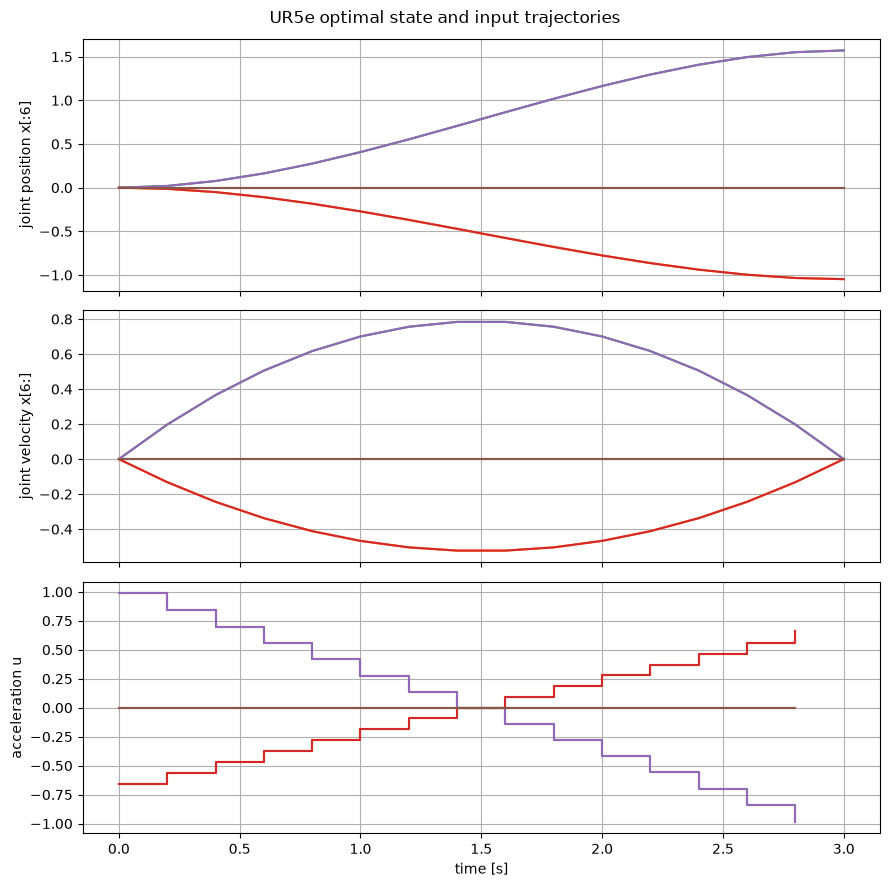

In [5]:
import casadi as ca
import matplotlib.pyplot as plt
import numpy as np

from casadi_tutorial.models.ur5e import (
    UR5eParameters,
    forward_kinematics,
)

parameters = UR5eParameters()
horizon_steps = 15
duration = 3.0
step_size = duration / horizon_steps

q_initial = np.zeros(6)
q_goal = np.array([0, -np.pi / 3, np.pi / 2, -np.pi / 3, np.pi / 2, 0])

q_symbol = ca.MX.sym("q", 6)
tool_position = ca.Function(
    "tool_position",
    [q_symbol],
    [forward_kinematics(q_symbol, parameters)[:3, 3]],
)
obstacle_center = 0.5 * (
    np.asarray(tool_position(q_initial).full()).ravel()
    + np.asarray(tool_position(q_goal).full()).ravel()
)
obstacle_radius = 0.08

optimization = ca.Opti()
# The state x stacks joint position q and joint velocity v; u is acceleration.
x = optimization.variable(12, horizon_steps + 1)
u = optimization.variable(6, horizon_steps)
q = x[:6, :]
v = x[6:, :]
obstacle_slack = optimization.variable(1, horizon_steps + 1)

optimization.subject_to(q[:, 0] == q_initial)
optimization.subject_to(q[:, -1] == q_goal)
optimization.subject_to(v[:, 0] == 0)
optimization.subject_to(v[:, -1] == 0)

for index in range(horizon_steps):
    optimization.subject_to(
        q[:, index + 1] == q[:, index] + step_size * v[:, index] + 0.5 * step_size**2 * u[:, index]
    )
    optimization.subject_to(v[:, index + 1] == v[:, index] + step_size * u[:, index])

optimization.subject_to(
    optimization.bounded(
        parameters.q_min[:, None],
        q,
        parameters.q_max[:, None],
    )
)
optimization.subject_to(
    optimization.bounded(
        -parameters.v_max[:, None],
        v,
        parameters.v_max[:, None],
    )
)
optimization.subject_to(
    optimization.bounded(
        -parameters.a_max[:, None],
        u,
        parameters.a_max[:, None],
    )
)
optimization.subject_to(obstacle_slack >= 0)

for index in range(horizon_steps + 1):
    squared_clearance = ca.sumsqr(tool_position(q[:, index]) - obstacle_center)
    optimization.subject_to(squared_clearance + obstacle_slack[0, index] >= obstacle_radius**2)

optimization.minimize(
    step_size * ca.sumsqr(u) + 1e4 * ca.sumsqr(obstacle_slack) + 1e-2 * ca.sumsqr(v)
)
for joint_index in range(6):
    optimization.set_initial(
        q[joint_index, :],
        np.linspace(
            q_initial[joint_index],
            q_goal[joint_index],
            horizon_steps + 1,
        ),
    )

optimization.solver(
    "ipopt",
    {"print_time": False},
    {"print_level": 0, "max_iter": 500},
)
solution = optimization.solve()
x_solution = solution.value(x)
u_solution = solution.value(u)
maximum_slack = np.max(solution.value(obstacle_slack))
print(
    "objective:",
    solution.value(optimization.f),
    "maximum slack:",
    maximum_slack,
)
assert solution.stats()["success"]
assert maximum_slack < obstacle_radius**2

x_time = np.linspace(0, duration, horizon_steps + 1)
u_time = x_time[:-1]
figure, axes = plt.subplots(3, 1, sharex=True, figsize=(9, 9))
axes[0].plot(x_time, x_solution[:6].T)
axes[0].set_ylabel("joint position x[:6]")
axes[1].plot(x_time, x_solution[6:].T)
axes[1].set_ylabel("joint velocity x[6:]")
axes[2].step(u_time, u_solution.T, where="post")
axes[2].set(xlabel="time [s]", ylabel="acceleration u")
for axis in axes:
    axis.grid(True)
figure.suptitle("UR5e optimal state and input trajectories")
figure.tight_layout()
plt.show()

### Measure the sparsity of the robot OCP constraints

The decision matrices are flattened with `ca.vec` and joined with
`ca.vertcat`. `ca.jacobian` then differentiates the complete Opti
constraint vector with respect to this explicit decision ordering.

Defining

$$
\begin{equation}
w=\operatorname{vertcat}(\operatorname{vec}(x),
\operatorname{vec}(u),
\operatorname{vec}(S)),
\end{equation}
$$

the inspected matrix is

$$
\begin{equation}
J_g(w)=\frac{\partial g}{\partial w}.
\end{equation}
$$

Its structural density is

$$
\begin{equation}
\rho=\frac{\operatorname{nnz}(J_g)}
{\operatorname{rows}(J_g)\operatorname{cols}(J_g)}.
\end{equation}
$$

Local dynamics and node-wise collision constraints make $\rho$ much
smaller than one, which sparse nonlinear solvers exploit.


In [6]:
# x contains all robot states and u contains the manipulated accelerations.
decision_vector = ca.vertcat(
    ca.vec(x),
    ca.vec(u),
    ca.vec(obstacle_slack),
)
constraint_jacobian = ca.jacobian(optimization.g, decision_vector)
jacobian_density = constraint_jacobian.nnz() / (
    constraint_jacobian.size1() * constraint_jacobian.size2()
)
print(
    "constraint Jacobian shape:",
    constraint_jacobian.shape,
    "structural nonzeros:",
    constraint_jacobian.nnz(),
    "density:",
    jacobian_density,
)

constraint Jacobian shape: (518, 298) structural nonzeros: 1048 density: 0.006789147728745044


A soft obstacle preserves feasibility while exposing collision pressure through slack. Production planning must check full link geometry continuously between nodes and use certified collision models. For mesh refinement, interpolate $Q,V,A$ onto the finer grid, seed the new problem, and compare objective and between-node clearance.

**Common mistakes:** checking only the tool point, trusting nodes between coarse intervals, and claiming dynamic feasibility from the surrogate. **Recap:** encode honest model limits, examine sparsity, and validate the continuous trajectory outside the NLP. [Exercises](../exercises/06_ur5e.ipynb).
